# Lorentz-equivariant neural fields and an invariant Lagrangian


In [1]:
import os
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

from a3_sol_th import analysis, plotting

get_ipython().run_line_magic("matplotlib", "inline")
plt.style.use("mphil.mplstyle")
SEED = 1123
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
DTYPE = np.float32
DATA_DIR = Path(os.environ.get("A3_DATA_DIR", "data")).expanduser()
TORCH_PHI_WEIGHTS = DATA_DIR / "weights_torch_phi.pt"
TORCH_W_WEIGHTS = DATA_DIR / "weights_torch_W.pt"
TRAIN_RANGE_MIN, TRAIN_RANGE_MAX = -5.0, 5.0
Path("figures").mkdir(exist_ok=True)


## Equivariant Neural Networks

Two course-provided, pretrained MLPs map spacetime coordinates $x^\mu=(t,x,y,z)$ to four real scalar-field components (NN1) and twelve vector-field components (NN2). Each has three ReLU hidden layers of width 128. This notebook compares their approximate Lorentz symmetry with architectures that impose it algebraically, trains those architectures to emulate the supplied outputs, and evaluates a free-field Lagrangian.

The supplied weights are external inputs; set `A3_DATA_DIR` or place them in `data/` as described in the README.


| Field | Output interpretation | Lorentz behaviour |
|---|---|---|
| $\Phi$ | Two complex components, with a chosen fundamental $SU(2)$ action | Scalar |
| $W^{\mu a}$ | Four spacetime components and three adjoint $SU(2)$ components | Four-vector |

The internal $SU(2)$ action is applied to field outputs. Output dimension alone does not establish a representation, and these networks have no internal-symmetry input on which to test an $SU(2)$ input-output equivariance relation.


In [2]:
nn1 = analysis.load_nn(TORCH_PHI_WEIGHTS, output_dim=4)
nn2 = analysis.load_nn(TORCH_W_WEIGHTS, output_dim=12)


def predict_nn1(X):
    '''Evaluate NN1 on numpy array X of shape (N, 4).'''
    return analysis.predict(nn1, X)


def predict_nn2(X):
    '''Evaluate NN2 on numpy array X of shape (N, 4). Returns (N, 12).'''
    return analysis.predict(nn2, X)


### NN1: Higgs-like scalar field

NN1 maps $x^\mu \to (\phi_0, \phi_1, \phi_2, \phi_3) \in \mathbb{R}^4$, interpreted as a Lorentz-scalar $SU(2)$ doublet (the analogue of the Higgs field).

In [3]:
# Test at the origin
X_test = np.array([[0.0, 0.0, 0.0, 0.0]]).astype(DTYPE)

print("NN1 output shape:", predict_nn1(X_test).shape)
print("NN1([0,0,0,0]) =", predict_nn1(X_test))


NN1 output shape: (1, 4)
NN1([0,0,0,0]) = [[ 1.0138464  -0.01207615  0.00967198 -0.01923794]]


#### $SU(2)$ fundamental representation

The four real outputs form a complex doublet
$$\Phi=(\phi_0+i\phi_1,\;\phi_2+i\phi_3)^T.$$
The chosen fundamental action is $\Phi\mapsto U\Phi$, where $U=\exp(i\alpha^a\sigma^a/2)\in SU(2)$. It preserves $\Phi^\dagger\Phi$.


The Pauli matrices give $U=\cos(\alpha/2)I+i\sin(\alpha/2)\hat n^a\sigma^a$, with $\alpha=|\boldsymbol\alpha|$. The implementation uses this form for global internal rotations.


#### Lorentz singlet

For the Lorentz-scalar hypothesis, compare $\mathrm{NN1}(\Lambda x)$ with $\mathrm{NN1}(x)$. A vector hypothesis instead compares it with $\Lambda\mathrm{NN1}(x)$. Rotations and boosts provide numerical diagnostics of the supplied function.


In [4]:
N_pts = 200
X_rand = np.random.uniform(-3.0, 3.0, size=(N_pts, 4)).astype(DTYPE)
phi_orig = predict_nn1(X_rand)

# Rotation: 90 degrees around z-axis
R = analysis.rotation_matrix(2, np.pi / 2)
X_rot = (R @ X_rand.T).T.astype(DTYPE)
phi_rot = predict_nn1(X_rot)
print(f"Rotation:  scalar |\u0394| = {np.mean(np.abs(phi_rot - phi_orig)):.4f}"
      f"(vector |\u0394| = {np.mean(np.abs(phi_rot - (R @ phi_orig.T).T)):.4f})")

# Boost: rapidity 0.3 along x-axis
B = analysis.boost_matrix(0, 0.3)
X_boost = (B @ X_rand.T).T.astype(DTYPE)
phi_boost = predict_nn1(X_boost)
print(f"Boost:     scalar |\u0394| = {np.mean(np.abs(phi_boost - phi_orig)):.4f}"
      f"(vector |\u0394| = {np.mean(np.abs(phi_boost - (B @ phi_orig.T).T)):.4f})")


Rotation:  scalar |Δ| = 0.0063(vector |Δ| = 0.0322)
Boost:     scalar |Δ| = 0.0043(vector |Δ| = 0.0300)


A smaller scalar residual supports the scalar interpretation for these sampled transformations.


The pretrained MLP is unconstrained, so residual symmetry error need not vanish.


### NN2: vector triplet

Reshape the twelve outputs as $W^{\mu a}$, with a contravariant Lorentz index $\mu$ and an internal triplet index $a$.


In [5]:
# Test at the origin
X_test = np.array([[0.0, 0.0, 0.0, 0.0]]).astype(DTYPE)
W_test = analysis.reshape_W(predict_nn2(X_test))

print("NN2 output shape:", predict_nn2(X_test).shape)
print("Reshaped W^{mu,a} at origin (4 Lorentz rows x 3 adjoint cols):")
print(W_test[0])


NN2 output shape: (1, 12)
Reshaped W^{mu,a} at origin (4 Lorentz rows x 3 adjoint cols):
[[ 0.07362042  0.01779465 -0.0083463 ]
 [-0.00796721 -0.03773166 -0.10067782]
 [-0.03332679 -0.03999585  0.07828656]
 [-0.02512536  0.04193106  0.09382577]]


#### $SU(2)$ adjoint representation

The chosen adjoint action on the internal index is
$$W^{\mu a}\mapsto R^{ab}(U)W^{\mu b},\qquad R^{ab}(U)=\tfrac12\operatorname{tr}(\sigma^aU\sigma^bU^\dagger).$$
The real matrix $R$ is orthogonal and preserves contractions over $a$.


#### Lorentz spin-1 (4-vector)

The Lorentz-vector diagnostic compares $W(\Lambda x)$ with $\Lambda W(x)$, leaving the internal index unchanged. The scalar diagnostic provides a comparison.


In [6]:
N_pts = 200
X_rand = np.random.uniform(-3.0, 3.0, size=(N_pts, 4)).astype(DTYPE)
W_orig = analysis.reshape_W(predict_nn2(X_rand))  # (N, 4, 3)

# One rotation: 90 degrees around z-axis
R = analysis.rotation_matrix(2, np.pi / 2)
X_rot = (R @ X_rand.T).T.astype(DTYPE)
W_rot = analysis.reshape_W(predict_nn2(X_rot))

W_vec = np.einsum("ij,njk->nik", R, W_orig) # Vector hypothesis:left multiply by rotation
diff_vector = np.mean(np.abs(W_rot - W_vec))
diff_scalar = np.mean(np.abs(W_rot - W_orig))
print(f"Rotation:  vector |\u0394| = {diff_vector:.4f} (scalar |\u0394| = {diff_scalar:.4f})")

# One boost: rapidity 0.3 along x-axis
B = analysis.boost_matrix(0, 0.3)
X_boost = (B @ X_rand.T).T.astype(DTYPE)
W_boost = analysis.reshape_W(predict_nn2(X_boost))

W_vec_b = np.einsum("ij,njk->nik", B, W_orig)
diff_vector_b = np.mean(np.abs(W_boost - W_vec_b))
diff_scalar_b = np.mean(np.abs(W_boost - W_orig))
print(f"Boost:     vector |\u0394| = {diff_vector_b:.4f} (scalar |\u0394| = {diff_scalar_b:.4f})")


Rotation:  vector |Δ| = 0.0340 (scalar |Δ| = 0.1236)
Boost:     vector |Δ| = 0.0194 (scalar |Δ| = 0.0427)


The smaller vector residual supports the four-vector interpretation for these sampled transformations.


## Architectures with exact Lorentz equivariance


The Minkowski norm $s=t^2-x^2-y^2-z^2$ is Lorentz invariant. A scalar function $g(s)$ and a vector function $x^\mu f^a(s)$ therefore have the required transformation laws, irrespective of the MLP weights. These are restricted function classes; no claim of complete expressivity is needed.


### Scalar architecture

A `1 → 128 → 128 → 128 → 4` MLP acts on $s$. Since $s(\Lambda x)=s(x)$, its output is Lorentz invariant. The four components are interpreted as the complex doublet above.


In [7]:
nn1_m = analysis.ScalarEquivariantNN1()
print("Test output shape:", nn1_m(torch.randn(5, 4)).shape)


Test output shape: torch.Size([5, 4])


### Vector architecture

A `1 → 128 → 128 → 128 → 3` MLP produces $f^a(s)$ and the network returns $W^{\mu a}=x^\mu f^a(s)$. Thus $W(\Lambda x)=\Lambda W(x)$ algebraically, up to floating-point evaluation.


In [8]:
nn2_m = analysis.VectorEquivariantNN2()
print("Test output shape:", nn2_m(torch.randn(5, 4)).shape)


Test output shape: torch.Size([5, 12])


### Emulation training

Adam minimises mean squared error against the supplied MLPs. Each step draws 256 fresh points uniformly from $[-5,5]^4$, for 2,000 scalar-model steps and 3,000 vector-model steps. A separate 2,000-point sample measures emulation error after training.


In [9]:
hist_m_nn1 = analysis.train_manual_nn(
    nn1_m, predict_nn1, n_steps=2000, batch_size=256, lr=1e-3,
    label="NN1_m", train_range=(TRAIN_RANGE_MIN, TRAIN_RANGE_MAX)
)



Training NN1_m for 2000 steps ...
  step    1/2000  MSE=1.020031  (0.0s)
  step  200/2000  MSE=0.000058  (0.1s)


  step  400/2000  MSE=0.000105  (0.2s)
  step  600/2000  MSE=0.000048  (0.3s)
  step  800/2000  MSE=0.000036  (0.4s)


  step 1000/2000  MSE=0.000064  (0.5s)
  step 1200/2000  MSE=0.000204  (0.6s)
  step 1400/2000  MSE=0.000037  (0.7s)


  step 1600/2000  MSE=0.000040  (0.8s)
  step 1800/2000  MSE=0.000047  (0.8s)
  step 2000/2000  MSE=0.000036  (0.9s)
  Final MSE: 0.000036


In [10]:
hist_m_nn2 = analysis.train_manual_nn(
    nn2_m, predict_nn2, n_steps=3000, batch_size=256, lr=1e-3,
    label="NN2_m", train_range=(TRAIN_RANGE_MIN, TRAIN_RANGE_MAX)
)



Training NN2_m for 3000 steps ...
  step    1/3000  MSE=4.679750  (0.0s)


  step  200/3000  MSE=0.001733  (0.1s)
  step  400/3000  MSE=0.001250  (0.2s)


  step  600/3000  MSE=0.003202  (0.3s)


  step  800/3000  MSE=0.001226  (0.4s)
  step 1000/3000  MSE=0.001083  (0.5s)


  step 1200/3000  MSE=0.001224  (0.6s)


...

  step 2200/3000  MSE=0.001268  (1.1s)


  step 2400/3000  MSE=0.001129  (1.2s)


  step 2600/3000  MSE=0.001682  (1.3s)


  step 2800/3000  MSE=0.001565  (1.4s)


  step 3000/3000  MSE=0.001331  (1.5s)
  Final MSE: 0.001331


In [11]:
def pred_nn1_m(X):
    '''Evaluate NN1_m on numpy array X of shape (N, 4).'''
    return analysis.predict(nn1_m, X)


def pred_nn2_m(X):
    '''Evaluate NN2_m on numpy array X of shape (N, 4). Returns (N, 12).'''
    return analysis.predict(nn2_m, X)


### Equivariance and emulation diagnostics

Compare all four networks under 30 random compositions of rotations and boosts.


In [12]:
n_transforms = 30

errs = analysis.compute_equivariance_errors(
    predict_nn1, predict_nn2,
    pred_nn1_m, pred_nn2_m,
    n_transforms=n_transforms, seed=SEED,
)


In [13]:
# Generate validation set
N_VAL = 2000

rng_data = np.random.default_rng(SEED)
X_val = rng_data.uniform(TRAIN_RANGE_MIN, TRAIN_RANGE_MAX,
                         size=(N_VAL, 4)).astype(DTYPE)

Y_val_1 = predict_nn1(X_val)
Y_val_2 = predict_nn2(X_val)


In [14]:
val_mse_m_nn1    = float(np.mean((pred_nn1_m(X_val) - Y_val_1) ** 2))
val_mse_m_nn2    = float(np.mean((pred_nn2_m(X_val) - Y_val_2) ** 2))

print(f"NN1 (pretrained) : mean eq. err = {errs['NN1_orig'].mean():.6g},  max eq. err = {errs['NN1_orig'].max():.6g}")
print(f"NN1_m (equivariant) : mean eq. err = {errs['NN1_m'].mean():.6g},  max eq. err = {errs['NN1_m'].max():.6g},  val MSE = {val_mse_m_nn1:.6g}")
print()
print(f"NN2 (pretrained) : mean eq. err = {errs['NN2_orig'].mean():.6g},  max eq. err = {errs['NN2_orig'].max():.6g}")
print(f"NN2_m (equivariant) : mean eq. err = {errs['NN2_m'].mean():.6g},  max eq. err = {errs['NN2_m'].max():.6g},  val MSE = {val_mse_m_nn2:.6g}")


NN1 (pretrained) : mean eq. err = 0.00669895,  max eq. err = 0.00887078
NN1_m (equivariant) : mean eq. err = 3.7824e-08,  max eq. err = 5.74844e-08,  val MSE = 4.45832e-05

NN2 (pretrained) : mean eq. err = 0.0442368,  max eq. err = 0.0752079
NN2_m (equivariant) : mean eq. err = 9.18687e-08,  max eq. err = 1.8408e-07,  val MSE = 0.00143045


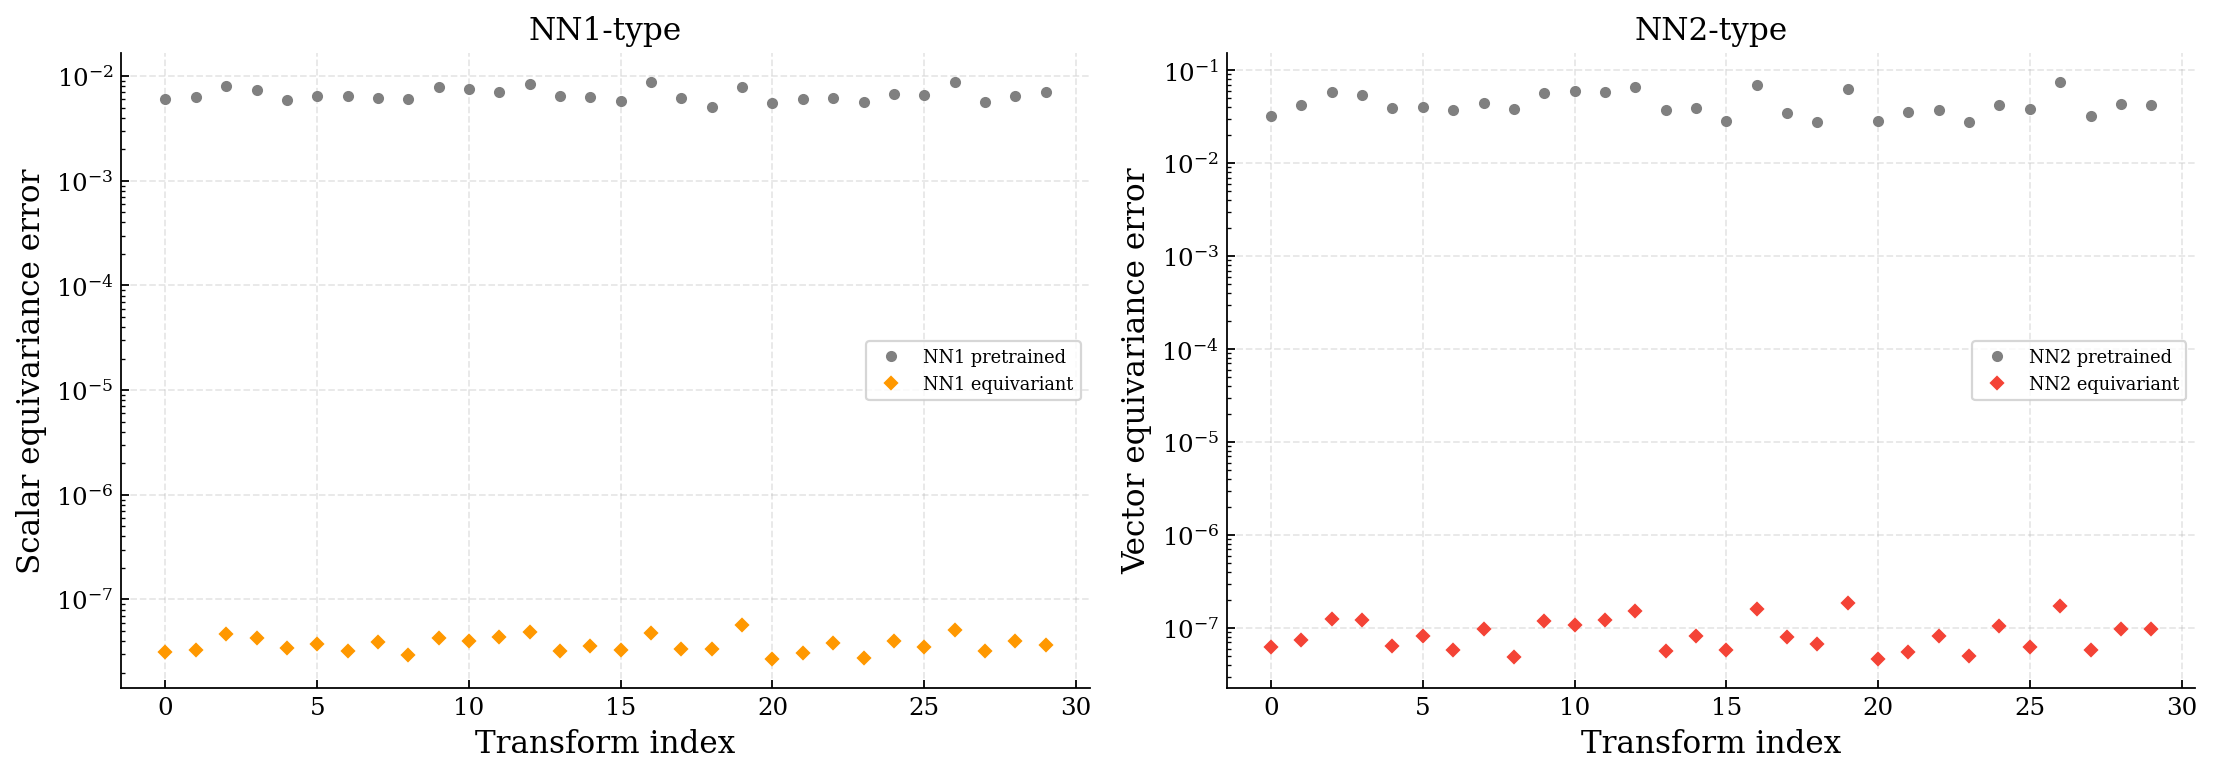

In [15]:
fig = plotting.plot_equivariance_errors(errs, n_transforms)
fig.savefig("figures/equivariance.png", dpi=160, bbox_inches="tight")


The constrained networks reduce Lorentz-equivariance error substantially. Emulation MSE measures a different property: how well a restricted architecture approximates the supplied MLP. Floating-point symmetry residuals depend on the model and input scale.


## Free-field Lagrangian

With $\eta=\operatorname{diag}(1,-1,-1,-1)$, use
$$\mathcal L=\partial_\mu\Phi^\dagger\partial^\mu\Phi-m_\Phi^2\Phi^\dagger\Phi-\tfrac14F_{\mu\nu}^aF^{a\mu\nu}+\tfrac12m_W^2W_\mu^aW^{a\mu},$$
where $F_{\mu\nu}^a=\partial_\mu W_\nu^a-\partial_\nu W_\mu^a$. Network outputs are contravariant, so the implementation lowers the vector index before forming $F_{\mu\nu}$. Set both masses to one in dimensionless units.

This is a free massive vector triplet and scalar doublet with **global** $SU(2)$ symmetry. It is not a locally gauge-invariant interacting electroweak model.


### Numerical derivatives

Central differences with step $\epsilon=10^{-3}$ approximate spacetime derivatives. Float32 cancellation and ReLU kinks also affect the result, so a universal $O(\epsilon^2)$ residual is not assumed.


In [16]:
M_PHI = 1.0          # scalar doublet mass
M_W   = 1.0          # vector triplet mass
EPS   = 1e-3         # finite-difference step


### Lorentz diagnostics

Compare $\mathcal L(\Lambda x)$ and $\mathcal L(x)$ for the equivariant field configurations at 100 points, using fixed transformations and twenty random rotation–boost combinations.


In [17]:
N_LAG = 100    # number of test points
np.random.seed(SEED)
X_lag = np.random.uniform(-1.0, 1.0, size=(N_LAG, 4)).astype(DTYPE)

L_orig = analysis.lagrangian_density(X_lag, pred_nn1_m, pred_nn2_m, m_phi=M_PHI, m_w=M_W, eps=EPS)
print(f"L(x):  mean={L_orig.mean():.4f},  std={L_orig.std():.4f}")

# fixed transformations
R   = analysis.rotation_matrix(2, np.pi / 2)   # 90 deg around z
B   = analysis.boost_matrix(0, 0.3)            # rapidity 0.3 along x

X_rot   = (R @ X_lag.T).T.astype(DTYPE)
X_boost = (B @ X_lag.T).T.astype(DTYPE)

L_rot   = analysis.lagrangian_density(X_rot, pred_nn1_m, pred_nn2_m, m_phi=M_PHI, m_w=M_W, eps=EPS)
L_boost = analysis.lagrangian_density(X_boost, pred_nn1_m, pred_nn2_m, m_phi=M_PHI, m_w=M_W, eps=EPS)

delta_rot   = np.mean(np.abs(L_rot   - L_orig))
delta_boost = np.mean(np.abs(L_boost - L_orig))

print(f"\nLorentz invariance of L:")
print(f"  Rotation (90 deg z):   mean|L(Rx) - L(x)| = {delta_rot:.6f}")
print(f"  Boost    (eta=0.3 x):  mean|L(Bx) - L(x)| = {delta_boost:.6f}")

# 20 random Lorentz transforms
lorentz_deltas = []
for _ in range(20):
    ax  = np.random.randint(0, 3)
    th  = np.random.uniform(0, 2 * np.pi)
    eta = np.random.uniform(-0.5, 0.5)
    Lam = analysis.boost_matrix(ax, eta) @ analysis.rotation_matrix(ax, th)
    X_t = (Lam @ X_lag.T).T.astype(DTYPE)
    lorentz_deltas.append(np.mean(np.abs(
        analysis.lagrangian_density(X_t, pred_nn1_m, pred_nn2_m, m_phi=M_PHI, m_w=M_W, eps=EPS) - L_orig
    )))

print(f"\n20 random Lorentz transforms:")
print(f"  mean delta = {np.mean(lorentz_deltas):.6f}")
print(f"  max  delta = {np.max(lorentz_deltas):.6f}")


L(x):  mean=-1.2681,  std=0.2382

Lorentz invariance of L:
  Rotation (90 deg z):   mean|L(Rx) - L(x)| = 0.000000
  Boost    (eta=0.3 x):  mean|L(Bx) - L(x)| = 0.000061

20 random Lorentz transforms:
  mean delta = 0.000095
  max  delta = 0.000155


### Global $SU(2)$ diagnostics

Apply $\Phi\mapsto U\Phi$ and $W^{\mu a}\mapsto R^{ab}(U)W^{\mu b}$ to the predicted fields. Recompute all terms, including finite-difference derivatives, for ten random global rotations.


In [18]:
# test with 10 random SU(2) elements
su2_deltas = []
for _ in range(10):
    U = analysis.random_su2()
    L_su2 = analysis.lagrangian_su2_transformed(
        X_lag, U, pred_nn1_m, pred_nn2_m, m_phi=M_PHI, m_w=M_W, eps=EPS
    )
    su2_deltas.append(np.mean(np.abs(L_su2 - L_orig)))

print("SU(2) global invariance of L:")
print(f"  10 random U in SU(2):")
print(f"  mean delta = {np.mean(su2_deltas):.6f}")
print(f"  max  delta = {np.max(su2_deltas):.6f}")


SU(2) global invariance of L:
  10 random U in SU(2):
  mean delta = 0.000005
  max  delta = 0.000006


### Lagrangian diagnostics


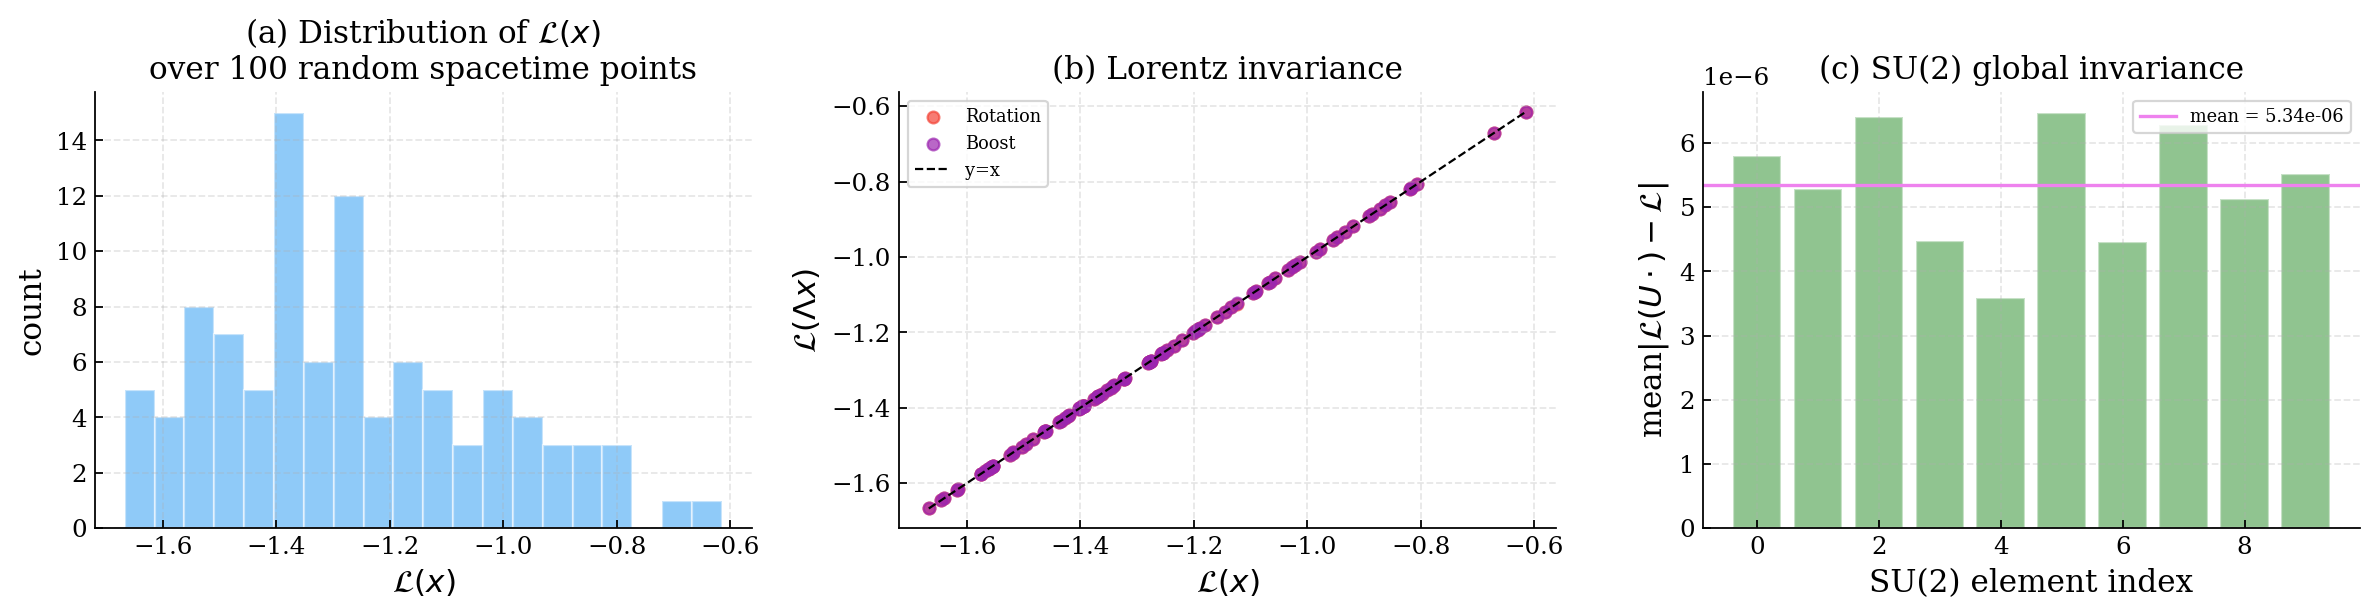

In [19]:
fig = plotting.plot_lagrangian_invariance(L_orig, L_rot, L_boost, delta_rot, delta_boost, su2_deltas)
fig.savefig("figures/lagrangian.png", dpi=160, bbox_inches="tight")


All Lorentz indices are contracted with the Minkowski metric. The internal contractions are preserved because $U$ is unitary and its adjoint matrix $R$ is orthogonal. Numerical residuals reflect finite differences, floating-point arithmetic and non-smooth network activations. These sampled checks are diagnostics rather than a proof for every field configuration.
